In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.linear_model import Ridge, Lasso

# Exercise 4 (4 points)

Predict whether a patient will experience disorientation within 12 hours of receiving a 100 mg dose of a new medication.

Predictors: body fat, meat in diet, stress level, blood oxygen, blood sugar.

In [3]:
training_data = pd.DataFrame({
    'fat':   [15.22442, 28.51168,  6.13891, 18.20264, 16.41537, 19.31584,  7.57312, 27.49562,  6.05149, 13.19802, 28.86259, 21.01267, 21.39264, 19.85355, 12.22899, 29.07561, 27.55748, 24.88669, 16.94490, 23.96149, 12.95453, 10.79064, 15.34311,  8.81112,  8.47015, 10.82585, 16.64906,  6.14578, 10.16328,  7.37102, 15.99579, 23.86188,  5.01562, 10.50297, 14.49541, 13.79495,  7.77839, 11.09049,  7.57162,  9.37632,  8.26739, 13.00933,  7.33987, 16.66948, 19.99972, 17.21533, 28.86185, 17.07256,  8.67737, 28.38250,  8.55736, 18.73212, 12.69300, 14.23722,  8.85506,  7.27610, 20.48141, 21.82498, 23.42694, 24.65704, 15.23687, 26.06823, 11.14309, 11.16122,  7.77741, 14.74986, 21.24963, 18.34220, 10.52757, 15.31865, 11.64217, 23.66420, 21.70712, 12.81120, 22.70726, 17.03225, 11.62582, 27.54686, 13.03707, 29.64102,  8.80867, 19.32168, 10.96815, 20.03414, 12.20598,  9.26613,  9.30429, 17.05107, 22.52133, 23.20986, 27.89209, 15.71054,  6.46196, 20.82638, 24.63229, 15.10998, 16.78941, 28.14270, 17.57033,  5.15752,  9.10528, 21.22045, 23.96483,  6.62321,  6.36573, 12.44354, 27.01101, 25.41515, 29.55351,  7.58999, 24.97079, 24.61438,  5.23575, 23.23477, 20.75330,  5.20539, 17.30733],
    'meat':  [121.7750, 141.3636,  94.5035, 184.0134, 135.3303, 148.9152, 233.9748,  92.9359, 242.5512,  65.6625, 253.7704, 128.0282, 179.7012,  56.3817, 297.2696, 284.7846, 221.9019, 254.1195, 234.7579, 137.1799, 183.8853, 118.6363, 258.0269, 238.2775, 291.0381,  70.3666, 263.5912, 131.8993, 196.7397, 282.3377, 271.2832, 188.3285, 155.8659, 227.2595, 153.3264, 191.6835, 172.5159, 269.6685, 268.4875, 195.6849, 181.6475,  72.0908, 134.3738, 273.5837, 109.3074, 106.4546, 129.6236,  93.4960, 143.5423, 207.4364, 245.4558, 272.9740, 243.8519,  60.5270, 118.4378, 262.6169, 239.7838, 164.4804, 232.4079, 238.0094, 249.7059,  72.5805, 125.1294, 191.7799, 234.1551, 264.3619,  79.3328,  68.7392,  89.2920, 211.7643,  93.3794, 120.7506, 155.1087, 228.6887, 257.8055, 187.6542, 180.5839, 113.4552, 208.7001, 184.8902, 157.1533, 138.9404, 261.2334,  55.7861, 144.1111,  96.4683, 157.2351, 207.6934, 146.1142, 235.6348,  55.7137, 268.7206, 281.1197, 199.3384, 172.4593, 272.0929,  59.1761, 178.4453, 213.3570, 253.2783, 251.8748, 252.1530, 114.7003, 100.8543, 120.7832, 283.4241, 172.3570, 151.9077,  75.9279, 120.1413, 114.8112, 167.6705, 141.4614,  61.7484, 115.6991, 169.4555, 216.9101],
    'stress':[16.01848, 84.77392, 47.78868, 77.36921, 44.05331, 50.69977,  1.91910, 77.36860, 64.14626, 46.84321, 27.92238, 58.55656, 81.12373, 45.54890, 26.88034, 23.12309, 54.32329, 13.02881, 54.79943, 14.92442, 42.68856, 44.77301, 45.68868, 24.24571,  7.58608, 39.12951,  1.31082, 70.88554, 27.64399, 17.30430, 56.19632, 78.84094, 80.04764, 62.89278, 27.14090, 41.98642, 35.54347, 39.23313, 75.93357, 48.01264, 80.62479, 73.87485, 62.45530, 28.86901, 80.09179, 21.70480, 74.42385, 86.66537, 66.05323,  7.22866, 24.43082, 42.18101, 71.86118, 13.83901, 93.10996, 56.83380, 54.02562, 70.29795, 56.77484, 28.80103, 40.53639, 21.71838, 32.82387, 91.89548, 52.87654, 37.19788, 45.92408,  7.24691, 28.69576, 14.94125, 97.24320, 91.63057, 21.66621, 21.05232, 67.90228, 13.49964, 38.74983, 59.42730, 55.50781, 44.94114, 96.85509, 38.51986, 85.85914, 48.90915, 15.76628, 78.53486, 54.21883, 41.65473, 81.36684, 11.16880, 53.09357, 27.75601, 58.87063, 44.02418, 86.59671, 24.45707, 98.15432, 24.87264, 97.28035, 72.52280, 56.61824, 39.21965, 20.20875, 73.55584, 34.61270, 81.57680, 84.81077, 30.33252, 77.05970, 73.34485, 56.90488,  2.62808, 48.61272, 83.66601, 72.86645, 13.65023,  9.96219],
    'oxygen':[83.6896, 90.8647, 86.6990, 87.5413, 87.9056, 76.6831, 82.6051, 82.5995, 81.4134, 82.6705, 75.7428, 91.9361, 91.9372, 82.5524, 89.3152, 95.0033, 90.8430, 82.4272, 77.5004, 81.2130, 97.9481, 84.2903, 79.9335, 90.2899, 78.3200, 71.5857, 82.7728, 99.0940, 79.5550, 79.3722, 95.9518, 78.2977, 80.7598, 92.3828, 70.8888, 77.6988, 84.9405, 89.6007, 94.3718, 80.4590, 93.8067, 79.8347, 75.3501, 92.2405, 89.1756, 77.6580, 94.6172, 94.1134, 84.0870, 86.7187, 81.7985, 88.2654, 71.7628, 84.0713, 87.4516, 75.6066, 93.8296, 82.6908, 89.6314, 77.7251, 94.8722, 84.0087, 81.8339, 81.4814, 70.9591, 85.6434, 78.2543, 82.0019, 81.7155, 82.7188, 78.5927, 92.3585, 76.1946, 86.1706, 99.8912, 71.0597, 85.7684, 98.5851, 72.4986, 77.7978, 84.6447, 75.6327, 91.3910, 83.8360, 87.8448, 99.6956, 88.4623, 78.1923, 98.3687, 86.6992, 75.9144, 83.4023, 98.1105, 70.1609, 84.9976, 82.0313, 83.4262, 90.5000, 97.2617, 89.1730, 88.0338, 84.1598, 74.8289, 98.9880, 90.3236, 77.2495, 95.0857, 79.9657, 89.3421, 98.7585, 85.3084, 74.6579, 95.3755, 90.0962, 88.5327, 87.4766, 85.5540],
    'sugar': [ 86.4098, 124.2110, 137.7977, 119.2165,  94.4018, 136.9460, 179.1374,  91.0309,  96.6626, 106.0197,  70.3889, 179.7458,  82.2624, 133.4980, 115.7982, 133.1609, 133.5399,  94.5221, 151.0157, 137.3644, 175.5863, 151.9320, 117.8817, 171.0932, 169.7367, 159.7064,  91.9728, 134.9433,  84.0553, 163.6432, 172.7028,  84.0571, 114.0314, 154.4359, 127.4085, 176.2366,  75.3884,  86.8639, 121.1025, 104.6850,  86.9146, 104.1532, 115.7383, 127.4459, 139.2826, 116.7186, 176.0146, 144.9098, 162.1275, 149.2690,  94.1815, 153.9417,  99.6936, 165.4600, 163.5029, 127.6326,  88.1005,  85.1849,  86.4693, 159.2210,  89.8967,  86.7809, 139.7575,  87.7186, 110.5968, 103.2440, 139.3319, 179.6168, 178.9080, 151.9837, 118.0425, 116.9203, 160.2858, 142.7013,  70.9589,  73.1000, 163.0031, 152.0505,  88.9258, 143.6688, 114.3601,  84.1183, 160.2181, 156.7157, 147.8048, 132.0036, 101.1089, 113.1262,  81.3519, 161.3834,  90.2796, 164.4737, 141.3023, 176.6171,  95.9863, 107.4494,  76.4230, 145.6844,  98.4506, 104.3051,  73.3602,  75.5183, 109.5803, 129.2459, 137.5516,  95.0392, 116.3993,  96.2021, 102.0794, 166.4035, 164.3029, 122.5013, 168.3654, 138.3177, 149.5037, 143.8684, 105.8116],
    'disorientation': [0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
})

val_data = pd.DataFrame({
    'fat':   [ 6.38255, 10.94374, 13.84965, 26.42214, 26.34408, 12.39739, 22.59980, 27.87659, 12.15713, 23.44494, 17.31416, 15.36838,  7.98512, 18.15074, 29.58375, 17.87680,  9.07676, 29.64885, 25.88138,  8.59543, 27.41847, 14.08251, 24.59866,  5.44415, 15.54612, 29.09608, 24.36479, 24.22985, 12.05546, 10.26218, 29.42748, 12.40755, 23.14958,  7.94785, 29.78091, 29.65136, 27.63274, 14.88622, 16.24506],
    'meat':  [271.0334,  81.5207, 197.4754, 190.4189, 222.1803, 127.8177, 297.7586, 233.4880, 242.9774, 165.7438, 193.0184, 290.6053, 234.0835, 203.1809, 274.5902, 297.9363, 228.7834, 159.0119, 272.2554, 156.1130, 211.8605, 204.4815, 117.7039,  78.5636,  85.1615, 218.3887,  53.2603,  87.1484, 124.4308, 105.7203, 191.4136, 239.1625, 217.4009,  62.7200, 249.4757, 280.9248, 263.0911, 217.0809, 177.8286],
    'stress':[23.68726, 25.51057, 54.80433,  3.39015, 80.61095, 33.77528, 35.71064, 64.14732, 32.03521, 58.14332, 17.03690, 30.22353, 45.65182, 38.43425, 29.10830, 13.13782,  2.48171, 47.55582, 48.88076, 64.88825, 83.69779, 23.34955, 29.88560, 58.55671, 33.92215, 82.35256, 37.39821,  7.58029, 86.95323, 23.48996, 99.30155, 67.81977, 43.54868,  5.32594, 23.71979, 23.32397,  6.17263, 24.41251, 75.81855],
    'oxygen':[90.6786, 83.4781, 88.0812, 70.1383, 99.8498, 82.1939, 96.0862, 93.0943, 85.0223, 97.7759, 79.4738, 80.1829, 84.4494, 82.4798, 89.2735, 83.8589, 72.1404, 87.3874, 98.1567, 87.2457, 72.6928, 85.0342, 76.6977, 96.5892, 78.4751, 98.0727, 82.4523, 77.3652, 81.7555, 88.0632, 86.2382, 99.7247, 77.6137, 73.3715, 86.0733, 83.3149, 74.7207, 86.8613, 86.5207],
    'sugar': [140.1384, 142.9693,  92.1768, 134.5545, 146.4577, 128.1117, 146.8320, 130.9489,  93.2212, 140.0033,  78.0529, 141.4933,  87.1985, 170.1158, 132.2852, 101.0591, 150.2976,  77.2895, 116.4625, 130.4727,  96.3994, 123.0886,  98.9132, 143.0732, 166.6565,  97.2321, 171.7536, 111.5294, 157.3796, 148.1768, 132.2279,  71.1127,  98.2646, 140.9932, 169.1219, 150.5554,  94.6809, 158.3037, 104.3649],
    'disorientation': [1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1]
})

print(training_data.head())

        fat      meat    stress   oxygen     sugar  disorientation
0  15.22442  121.7750  16.01848  83.6896   86.4098               0
1  28.51168  141.3636  84.77392  90.8647  124.2110               1
2   6.13891   94.5035  47.78868  86.6990  137.7977               0
3  18.20264  184.0134  77.36921  87.5413  119.2165               0
4  16.41537  135.3303  44.05331  87.9056   94.4018               0


Using all the concepts and models covered so far, build the best solution you can.

**Note:** you are evaluated on your **process** (including hyperparameter search), not just the final model.

In [4]:
#  Data prep
X_train = training_data.drop('disorientation', axis=1)
X_val = val_data.drop('disorientation', axis=1)

y_train = training_data['disorientation']
y_val = val_data['disorientation']

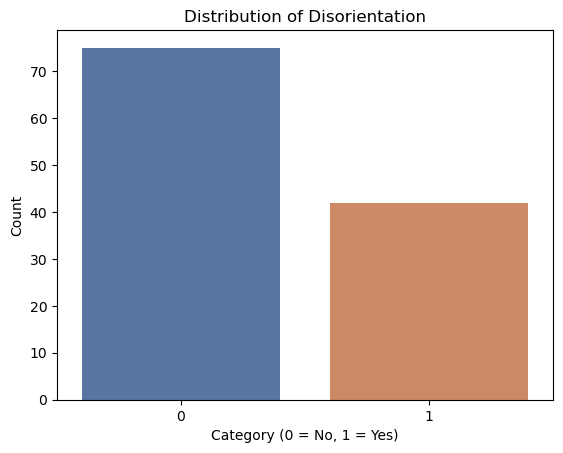

In [5]:
#  EDA
#  This is a problem of supervised binary classification
#  Let's take a look at the variables we are going to be working with

sns.countplot(x='disorientation', data=training_data, hue= 'disorientation', legend=False, palette='deep')

plt.title('Distribution of Disorientation')
plt.xlabel('Category (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

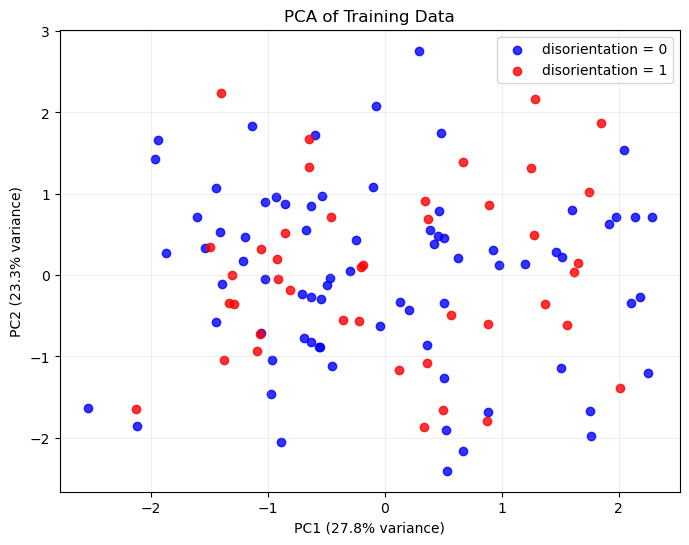

In [6]:
from sklearn.decomposition import PCA

# Scale features and compute 2D PCA
X_train_scaled = StandardScaler().fit_transform(X_train)
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)

# Plot points by class: 0 -> blue, 1 -> red
y_arr = y_train.to_numpy()

plt.figure(figsize=(8, 6))
plt.scatter(
    X_train_pca[y_arr == 0, 0],
    X_train_pca[y_arr == 0, 1],
    c="blue",
    alpha=0.8,
    label="disorientation = 0"
)
plt.scatter(
    X_train_pca[y_arr == 1, 0],
    X_train_pca[y_arr == 1, 1],
    c="red",
    alpha=0.8,
    label="disorientation = 1"
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("PCA of Training Data")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

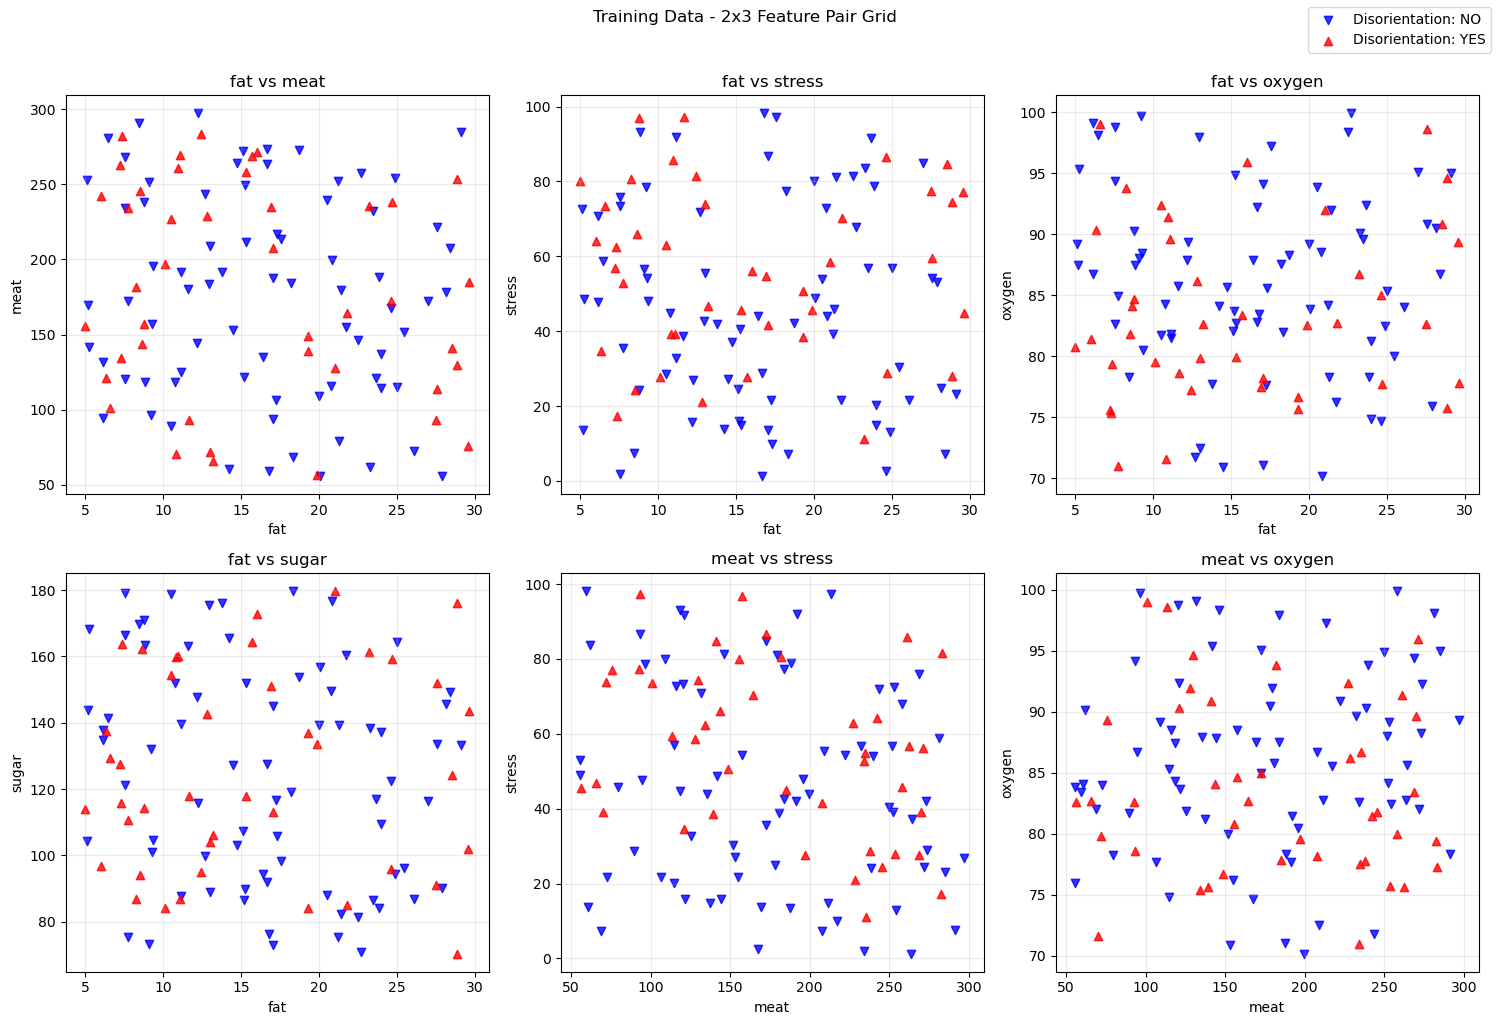

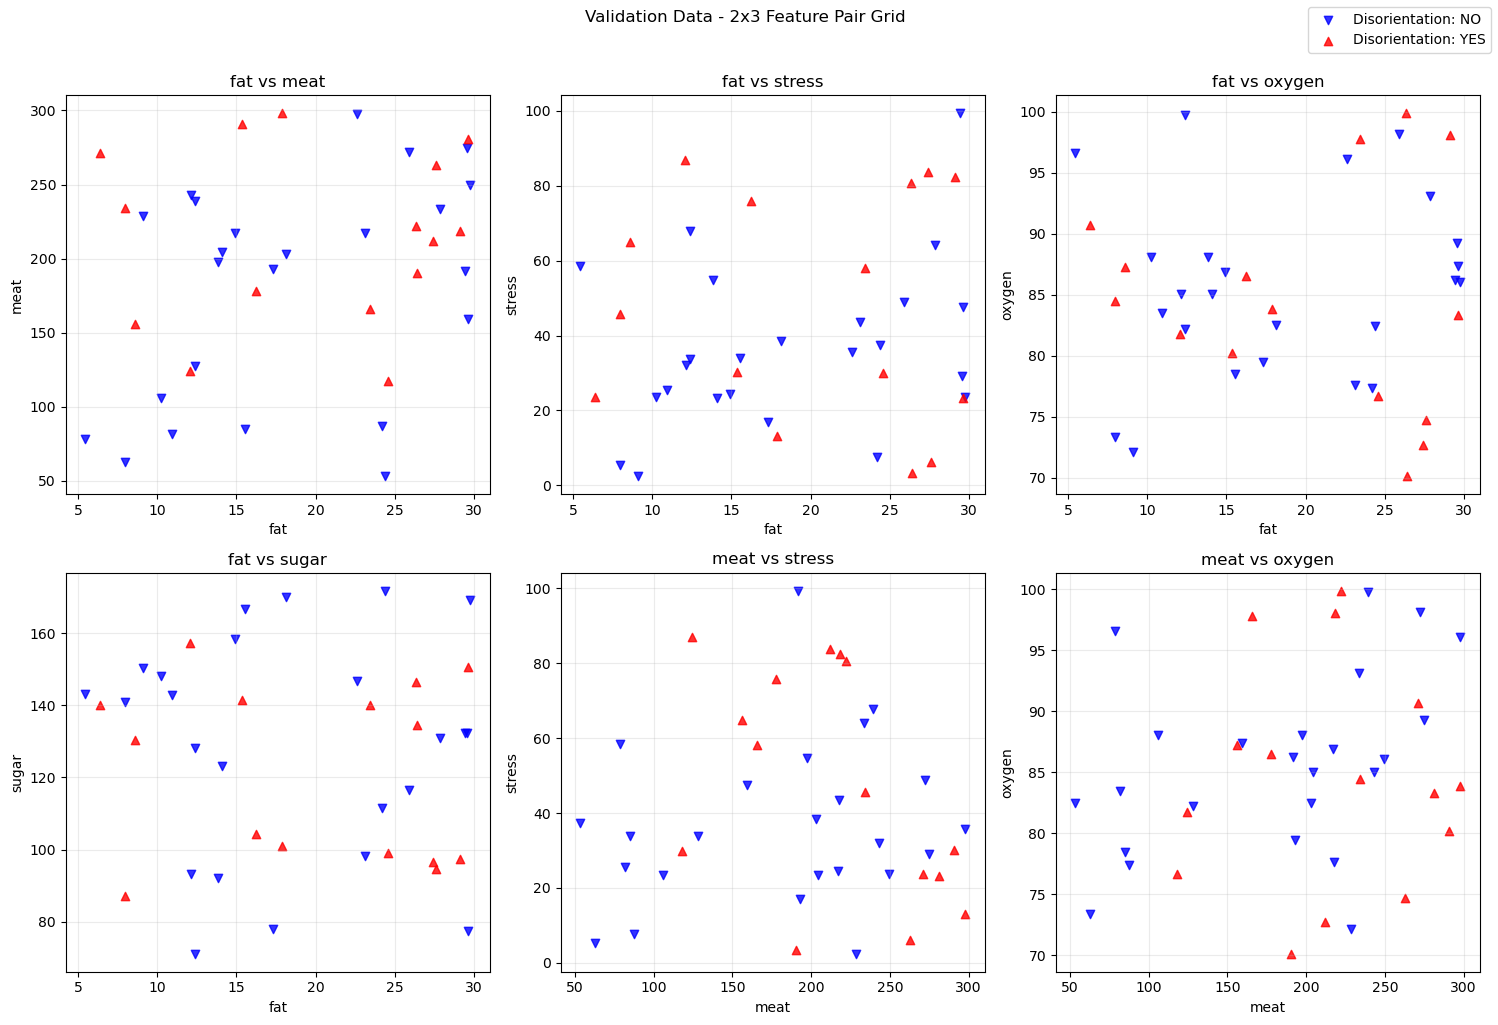

In [11]:
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt

def create_pair_grid(dataset_label, X, y, nrows=2, ncols=3):
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 10))
    axes = axes.ravel()

    # All pair combinations of the 5 variables
    pairs = list(combinations(X.columns, 2))
    pairs_to_plot = pairs[: nrows * ncols]  # 6 pairs for a 2x3 grid

    y_np = y.to_numpy() if hasattr(y, "to_numpy") else np.asarray(y)

    for ax, (x_col, y_col) in zip(axes, pairs_to_plot):
        for label, marker, color in [(0, "v", "blue"), (1, "^", "red")]:
            mask = y_np == label
            disorientation = "YES" if label == 1 else "NO"

            ax.scatter(
                X.loc[mask, x_col],
                X.loc[mask, y_col],
                marker=marker,
                color=color,
                alpha=0.8,
                label=f"Disorientation: {disorientation}"
            )

        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f"{x_col} vs {y_col}")
        ax.grid(True, alpha=0.25)

    # Hide any extra axes (not needed here, but safe)
    for ax in axes[len(pairs_to_plot):]:
        ax.axis("off")

    # One legend for the whole figure
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[:2], labels[:2], loc="upper right")
    fig.suptitle(f"{dataset_label} - 2x3 Feature Pair Grid", y=1.02)
    plt.tight_layout()
    plt.show()

create_pair_grid("Training Data", X_train, y_train)
create_pair_grid("Validation Data", X_val, y_val)

### Logistic Regression

Best Hyperparameters: {'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs', 'poly': 'passthrough', 'scaler': 'passthrough'}
Optimal classification threshold (OOF): 0.31

Training accuracy: 0.6410256410256411
Validation accuracy: 0.6923076923076923
Training F1: 0.5961538461538461
Validation F1: 0.6
Validation ROC-AUC: 0.7222222222222223

Validation classification report:

              precision    recall  f1-score   support

           0       0.75      0.75      0.75        24
           1       0.60      0.60      0.60        15

    accuracy                           0.69        39
   macro avg       0.68      0.68      0.68        39
weighted avg       0.69      0.69      0.69        39



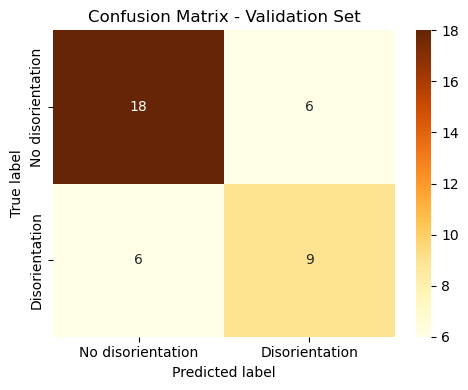

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ('poly', 'passthrough'),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=10000))
])

param_grid = [
    {
        'poly': [PolynomialFeatures(degree=2, include_bias=False),
                 PolynomialFeatures(degree=3, include_bias=False)],
        'scaler': [StandardScaler(), MinMaxScaler()],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0],
        'model__solver': ['lbfgs'],
        'model__class_weight': [None, 'balanced'],
    },
    {
        'poly': ['passthrough'],
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0],
        'model__solver': ['lbfgs'],
        'model__class_weight': [None, 'balanced'],
    },
]

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='f1_macro'
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# OOF probs from the best pipeline config (already fitted on full train)
# cross_val_predict refits the pipeline on each fold — correct behaviour
oof_probs = cross_val_predict(
    best_model, X_train, y_train,
    cv=cv, method='predict_proba'
)[:, 1]

# Tune threshold on OOF probs vs true train labels
best_threshold = 0.5
best_f1 = 0

for thresh in np.arange(0.1, 0.9, 0.01):
    preds = (oof_probs >= thresh).astype(int)
    score = f1_score(y_train, preds)
    if score > best_f1:
        best_f1 = score
        best_threshold = thresh

train_probs = best_model.predict_proba(X_train)[:, 1]
val_probs   = best_model.predict_proba(X_val)[:, 1]

train_preds = (train_probs >= best_threshold).astype(int)
val_preds   = (val_probs   >= best_threshold).astype(int)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Optimal classification threshold (OOF): {best_threshold:.2f}")
print()
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))
print("Validation ROC-AUC:", roc_auc_score(y_val, val_probs))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlOrBr',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.tight_layout()
plt.show()

*Although the number of false positives increases when optimizing for F1-score, the model now detects more true disorientation cases and reduces the number of false negatives. Since, in a medical setting, failing to identify a patient at risk is usually more problematic than issuing some extra false alarms, this trade-off is preferable.*

*However, logistic regression does not appear to be the most suitable model for this particular binary classification problem, as its overall performance remains limited even after adjusting the evaluation criterion and accounting for class imbalance.*

### SVM

Fitting 5 folds for each of 510 candidates, totalling 2550 fits
Best Hyperparameters: {'model__C': 1.0, 'model__class_weight': 'balanced', 'model__kernel': 'linear', 'scaler': StandardScaler()}
Optimal classification threshold (OOF): 0.37

Training accuracy: 0.6752136752136753
Validation accuracy: 0.6410256410256411
Training F1: 0.6122448979591837
Validation F1: 0.5333333333333333
Validation ROC-AUC: 0.6888888888888889

Validation classification report:

              precision    recall  f1-score   support

           0       0.71      0.71      0.71        24
           1       0.53      0.53      0.53        15

    accuracy                           0.64        39
   macro avg       0.62      0.62      0.62        39
weighted avg       0.64      0.64      0.64        39



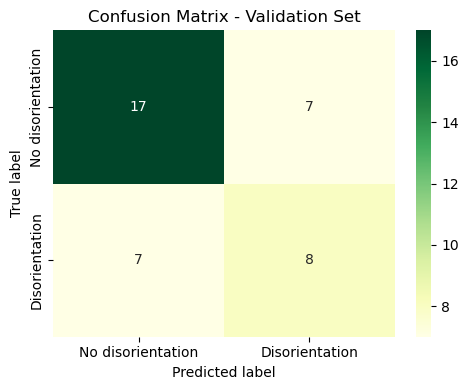

In [37]:
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(probability=True))  # needed for predict_proba + threshold tuning
])

param_grid = [
    # Linear kernel — gamma irrelevant
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__kernel': ['linear'],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
        'model__class_weight': [None, 'balanced'],
    },
    # RBF kernel — gamma matters, no degree/coef0
    {
        'scaler': [StandardScaler(), MinMaxScaler(), 'passthrough'],
        'model__kernel': ['rbf'],
        'model__C': [0.001, 0.01, 0.1, 0.5, 1.0, 5.0, 10.0],
        'model__gamma': ['scale', 'auto', 0.001, 0.01, 0.1, 1.0],
        'model__class_weight': [None, 'balanced'],
    },
    # Poly kernel — degree and coef0 matter
    {
        'scaler': [StandardScaler(), MinMaxScaler()],
        'model__kernel': ['poly'],
        'model__C': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0],
        'model__degree': [2, 3, 4],
        'model__coef0': [0.0, 0.5, 1.0],
        'model__class_weight': [None, 'balanced'],
    },
]

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='f1_macro',
    n_jobs=-1,
    verbose = 1
          # SVM grid is expensive — parallelise
)

grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_

# OOF threshold tuning — same approach as logistic regression
oof_probs = cross_val_predict(
    best_model, X_train, y_train,
    cv=cv, method='predict_proba'
)[:, 1]

best_threshold = 0.5
best_f1 = 0

for thresh in np.arange(0.1, 0.9, 0.01):
    preds = (oof_probs >= thresh).astype(int)
    score = f1_score(y_train, preds)
    if score > best_f1:
        best_f1 = score
        best_threshold = thresh

train_probs = best_model.predict_proba(X_train)[:, 1]
val_probs   = best_model.predict_proba(X_val)[:, 1]

train_preds = (train_probs >= best_threshold).astype(int)
val_preds   = (val_probs   >= best_threshold).astype(int)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Optimal classification threshold (OOF): {best_threshold:.2f}")
print()
print("Training accuracy:", accuracy_score(y_train, train_preds))
print("Validation accuracy:", accuracy_score(y_val, val_preds))
print("Training F1:", f1_score(y_train, train_preds))
print("Validation F1:", f1_score(y_val, val_preds))
print("Validation ROC-AUC:", roc_auc_score(y_val, val_probs))

print("\nValidation classification report:\n")
print(classification_report(y_val, val_preds))

cm = confusion_matrix(y_val, val_preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='YlGn',
    xticklabels=['No disorientation', 'Disorientation'],
    yticklabels=['No disorientation', 'Disorientation']
)
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Confusion Matrix - Validation Set')
plt.tight_layout()
plt.show()

*The SVM model provides a substantially better balance between the two classes than logistic regression. According to the confusion matrix, it correctly identifies 8 positive cases of disorientation while reducing the number of false negatives to 7. Although the number of false positives also increases compared with the logistic regression model, the trade-off is preferable in this medical setting, where missing a patient at risk is generally more serious than issuing an additional false alarm.*

*Overall, the SVM achieves a more balanced classification behaviour and shows a better ability to detect the positive class. This suggests that the relationship between the predictors and the target is not captured well enough by a purely linear probabilistic model such as logistic regression, whereas SVM is able to find a more suitable separating boundary for this dataset.*